In [4]:
from hac.convex_forward import get_unit_vectors, convex_forward_model_gpu
from hac.constants import CAMERA_ANGLE_ALPHA
from hac.data import get_model_stl_path, load_data
import matplotlib.pyplot as plt
import numpy as np

Testing convex forward operator and comparing with blender data

In [5]:
asteroid = 2

alphas_dict = CAMERA_ANGLE_ALPHA
stl_path = str(get_model_stl_path(asteroid))
ds_real = load_data(asteroid, "real", "intensity")
ds_blender = load_data(asteroid, "simulated", "intensity")
e_sun = np.array([-1.0, 0.0, 0.0])
blender_data = {key: ds_blender.data[key].values for key in alphas_dict}
alphas_items = list(alphas_dict.items())

## Parallel forward simulation for all 28 camera angles

Runs `convex_forward_model_gpu` for each of the 28 camera angles using `multiprocessing.ProcessPoolExecutor`, then saves the results in the same CSV format as `Asteroid01_lightcurve_binary_blender.txt` and compares with the real light curve.

In [ ]:
import numpy as np
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
import seaborn as sns

from hac.convex_forward import _run_single_camera

# --- Configuration ---
asteroid = 2
scattering_law = "LSL"
Lambert_weight = 0.1
n_phases = 360
e_sun = np.array([-1.0, 0.0, 0.0], dtype=np.float32)

stl_path = str(get_model_stl_path(asteroid))
cam_keys = list(CAMERA_ANGLE_ALPHA.keys())  # 28 camera angles in txt-file column order

# Build one arg-tuple per camera angle
task_args = [
    (cam_key, CAMERA_ANGLE_ALPHA[cam_key], stl_path, e_sun.tolist(),
     scattering_law, Lambert_weight, n_phases)
    for cam_key in cam_keys
]

# ThreadPoolExecutor
max_gpu_workers = 4
print(f"Running {len(task_args)} camera angles with {max_gpu_workers} concurrent GPU workers...")

results = {}
with ThreadPoolExecutor(max_workers=max_gpu_workers) as executor:
    futures = {executor.submit(_run_single_camera, args): args[0] for args in task_args}
    for future in futures:
        cam_key, phases, brightness = future.result()
        results[cam_key] = brightness
        print(f"  done: {cam_key}")

print("Simulation complete.")

# Assemble DataFrame with columns in the same order as the blender txt file
sim_df = pd.DataFrame(
    {k: results[k] for k in cam_keys},
    index=np.arange(1, n_phases + 1)
)
sim_df.index.name = "frame"

# Save in the same CSV format as Asteroid01_lightcurve_binary_blender.txt
output_path = f"/zhome/95/1/155570/HAC-DTU/workspaces/christian/sim_data/forward_sim_asteroid{asteroid:02d}.txt"
sim_df.to_csv(output_path, header=False, float_format="%.16f")
print(f"Saved to {output_path}")

Running 28 camera angles with 4 concurrent GPU workers...
  done: 0_hor1
  done: 0_hor2
  done: 0_top
  done: 0_bottom
  done: 45_hor1
  done: 45_hor2
  done: 45_top
  done: 45_bottom
  done: 90_hor1
  done: 90_hor2
  done: 90_top
  done: 90_bottom
  done: 135_hor1
  done: 135_hor2
  done: 135_top
  done: 135_bottom
  done: 225_hor1
  done: 225_hor2
  done: 225_top
  done: 225_bottom
  done: 270_hor1
  done: 270_hor2
  done: 270_top
  done: 270_bottom
  done: 315_hor1
  done: 315_hor2
  done: 315_top
  done: 315_bottom
Simulation complete.
Saved to /zhome/95/1/155570/HAC-DTU/workspaces/christian/sim_data/forward_sim_asteroid02_lightcurve_binary.txt


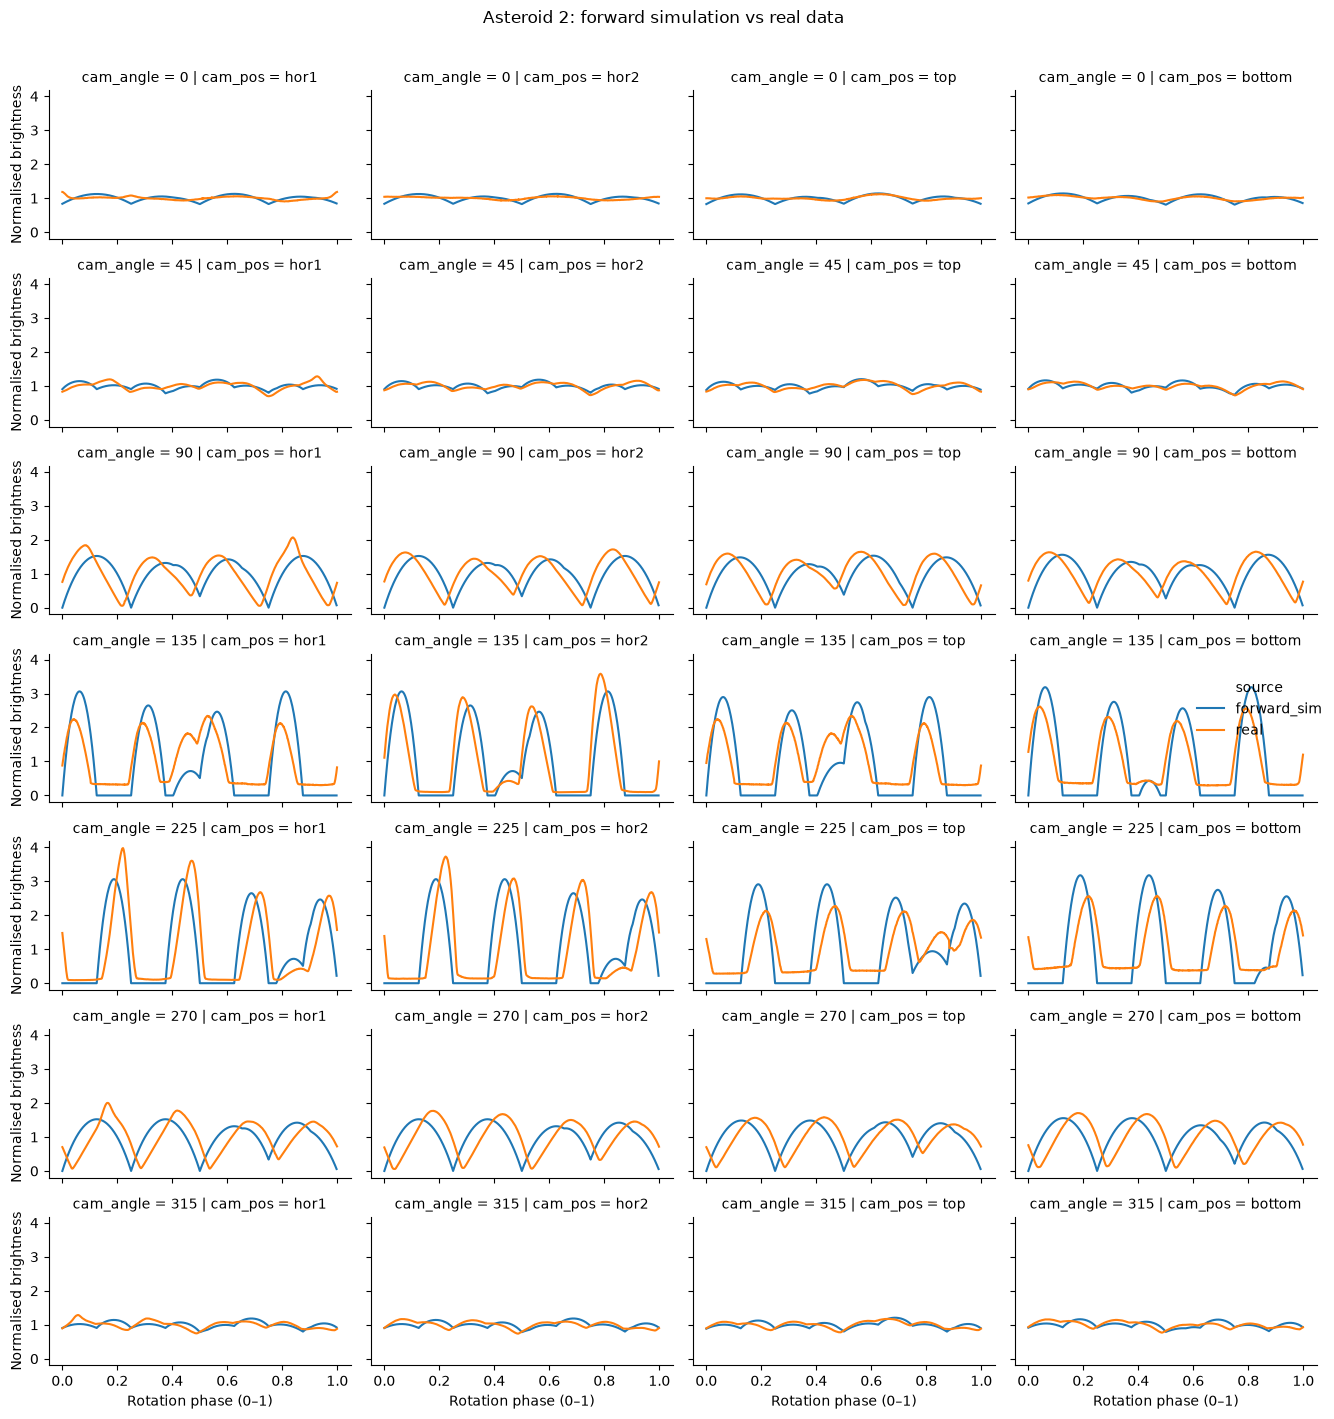

In [7]:


# --- Build long-format DataFrames ---
sim_long = (
    sim_df.reset_index()
    .melt(id_vars="frame", var_name="camera", value_name="value")
)
sim_long[["cam_angle", "cam_pos"]] = sim_long["camera"].str.split("_", n=1, expand=True)
sim_long["cam_angle"] = sim_long["cam_angle"].astype(int)
sim_long["source"] = "forward_sim"

real_long = ds_real.melt_data_to_long()
real_long["source"] = "real"

# Normalise frame index to rotation phase [0, 1) so curves with different
# sample counts are comparable on the same x-axis
sim_long["phase"] = (sim_long["frame"] - 1) / n_phases
real_long["phase"] = (real_long["frame"] - 1) / len(ds_real.data)

combined = pd.concat(
    [
        sim_long[["phase", "cam_angle", "cam_pos", "value", "source"]],
        real_long[["phase", "cam_angle", "cam_pos", "value", "source"]],
    ],
    ignore_index=True,
)

# --- Plot ---
g = sns.relplot(
    data=combined,
    x="phase",
    y="value",
    hue="source",
    row="cam_angle",
    col="cam_pos",
    kind="line",
    height=2,
    aspect=1.5,
)
g.set_axis_labels("Rotation phase (0\u20131)", "Normalised brightness")
g.fig.suptitle(
    f"Asteroid {asteroid}: forward simulation vs real data", y=1.01
)
plt.tight_layout()
plt.show()